In [3]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [4]:
#import database/data

In [5]:
conn = sqlite3.connect("customer_churn.db")


sql_query="""
       SELECT name
       from sqlite_master
       WHERE type='table';

"""

tables=pd.read_sql(sql_query,conn)
print("Tables found:")
print(tables)
#create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f'SELECT * FROM "{table_name}"', conn)

    globals()[f'df_{table_name}'] = df

    print(f"Created dataframe: df_{table_name}")
   

conn.close()

Tables found:
              name
0      db_customer
1  db_subscription
2       db_support
Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [6]:
#2data cleaning

In [7]:
 #df_db_customer.head()
 df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,None,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,None,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,None,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,None,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,None,None


In [8]:
 df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     object
 1   name        21 non-null     object
 2   country     18 non-null     object
 3   state       21 non-null     object
 4   gender      21 non-null     object
 5   dob         21 non-null     object
 6   interests   4 non-null      object
 7   pincode     0 non-null      object
dtypes: object(8)
memory usage: 1.4+ KB


In [9]:
#a.  rename col -name
#b.  droup interest and pincode
#c.  change data type -dob 
#d.  data standardization -gender
#e. fix missing value -country


In [10]:
#a.  rename col -name
df_db_customer.rename(columns ={'name' : 'customer_name'},inplace = True)  

In [11]:
#b.  droup interest and pincode

#df_db_customer.drop(df_db_customer.columns[-2:],axis=1)
#df_db_customer.drop(df_db_customer.columns[6:],axis=1)

df_db_customer.drop(columns=['interests','pincode'],inplace=True)

In [12]:
#c.  change data type -dob 

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [13]:
#d.  data standardization -gender

#df_db_customer['gender'].unique()
df_db_customer['gender']=df_db_customer['gender'].replace({'Men' : 'Male','Women' :'Femal'})

In [14]:
#e. fix missing value -country

df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,None,Delhi,Femal,1988-12-10
8,0015-UOCOJ,maya,None,Kathmandu,Femal,1985-07-07
12,0018-NYROU,chitra,None,Telangana,Female,2004-12-01


In [15]:
#country and state -unique value pair

state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

df_db_customer['country']=df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [16]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [17]:
df_db_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,India,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,Nepal,Kathmandu
9,Nepal,Kathmandu


In [18]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [19]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     object 
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     object 
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     object 
 5   contract_type            21 non-null     object 
 6   cancellation_date        6 non-null      object 
 7   cancellation_reason      6 non-null      object 
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 1.9+ KB


In [20]:
date_col= ['subscription_start_date', 'renewal_date','cancellation_date']

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)

df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     object        
 1   subscription_start_date  21 non-null     datetime64[ns]
 2   subscription_type        21 non-null     object        
 3   renewal_date             21 non-null     datetime64[ns]
 4   plan_type                21 non-null     object        
 5   contract_type            21 non-null     object        
 6   cancellation_date        6 non-null      datetime64[ns]
 7   cancellation_reason      6 non-null      object        
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 1.9+ KB


In [21]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,None
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,None


In [22]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      object
 1   complaint_date  9 non-null      object
 2   escalations     9 non-null      object
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      object
dtypes: int64(1), object(5)
memory usage: 564.0+ bytes


In [23]:
df_db_support.drop(columns=['col_1','comment'],inplace=True)

In [24]:
df_db_support['complaint_date']=pd.to_datetime(df_db_support['complaint_date'])

df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      object        
 1   complaint_date  9 non-null      datetime64[ns]
 2   escalations     9 non-null      object        
 3   csat_score      9 non-null      int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 420.0+ bytes


In [25]:
# 3. Feature Engineering and Data Analysis

In [26]:
#create a new col using existing col - churn flag
df_db_subscription['churn_flag']= np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [27]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [28]:
#first fix support table duplicates then merge
df = (df_db_subscription
             .merge(df_db_customer , on ='customerid', how='left')
             .merge(df_db_support , on ='customerid', how='left'))

In [29]:
df_db_subscription.shape

(21, 12)

In [30]:
df.shape

(23, 20)

In [31]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,N,60.0
2,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0
3,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN
4,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN


In [32]:
df_db_subscription['customerid'].nunique()

21

In [33]:
df_db_customer['customerid'].nunique()

21

In [34]:
df_db_support['customerid'].nunique()

7

In [35]:
df_db_support['customerid'].size

9

In [36]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [37]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [38]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid' ,keep = 'last')

In [39]:
df_db_support['customerid'].nunique()



7

In [40]:
df_db_support['customerid'].size

7

In [41]:
# merge df
df = (df_db_subscription
             .merge(df_db_customer , on ='customerid', how='left')
             .merge(df_db_support , on ='customerid', how='left'))

In [42]:
df.shape

(21, 21)

In [43]:
df.to_csv('exported_churn_data.csv', index=False)

In [44]:
# data Analysis

In [45]:
# 1. churn Rate

In [46]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [47]:
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ",round(churn_rate,2),"%")

Churn Rate =  28.57 %


In [48]:
#2. Retention Rate
retention_rate = 100-churn_rate
print("Retention Rate = ",round(retention_rate,2),"%")

Retention Rate =  71.43 %


In [49]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0


In [50]:
#3. churn by plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))

print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [51]:
#4 a. churn by state +sum(reveneue) & count of users 
#4 b. churn by subscription type +sum(reveneue) & count of users 

In [52]:
#4 a. churn by state +sum(reveneue) & count of users 
churn_by_state = (df.groupby('state')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_state_pct'))

print(churn_by_state)

           state  churn_state_pct
0          Delhi            25.00
1      Karnataka           100.00
2      Kathmandu             0.00
3    Maharashtra             0.00
4      Meghalaya            66.67
5       Nagaland             0.00
6      Rajasthan             0.00
7      Telangana            50.00
8  Uttar Pradesh             0.00


In [53]:
#4 b. churn by subscription type +sum(reveneue) & count of users 
churn_by_subscrip_type = (df.groupby('subscription_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_subscription_pct'))

print(churn_by_subscrip_type)

  subscription_type  churn_subscription_pct
0           Organic                    0.00
1              Paid                   16.67
2          Refferal                   83.33


In [54]:
#5 ARPU - Avg Revenue per user
arpu = df['monthly_charges'].mean()
print("ARPU = ",round(arpu,2))

ARPU =  18.85


In [55]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [56]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0


In [57]:
#6 Average customer Tenure
#count of days user has used our service : cancellation date else current date 
today = pd.Timestamp.today()

df['tenure_days'] = np.where(
   df['cancellation_date'].notna(),\
    
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,

    (today- df['subscription_start_date']).dt.days
    
)
avg_tenure = df['tenure_days'].mean()
print("Avg tenure days = ",round(avg_tenure,0))

Avg tenure days =  1587.0


In [58]:
#7 Revenue at risk - revenue lost from churned users
revenue_at_risk = df.loc[df['churn_flag']==1,'monthly_charges'].sum()
print("Revenue At Risk (Rs Laks) =",revenue_at_risk)

Revenue At Risk (Rs Laks) = 73.94


In [59]:
# 8. Esclation Rate

#df['escalations'].unique()

escaltion_rate = (df['escalations']=='Y').mean()*100
print("Esclation rate = ",round(escaltion_rate,2),"%")

Esclation rate =  19.05 %


In [60]:
#9. Avg Complaint per User
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg Complaints per user =", round(avg_complaints,2))

Avg Complaints per user = 0.43


In [61]:
df['escalations'] = df['escalations'].astype('object')

df.loc[
   df['customerid'].isin(['0003-MKNFE', '0013-EXCHZ','0017-IUDMW','0019-EFAEP','0022-TCJCI']),
   'escalations'
] = 'Y'

In [64]:
#10. Correlation  Esclation vs Churn
corr_df = df[['escalations', 'churn_flag']].dropna()

#df['escalations'] =np.where(df['escalations'] == 'Y',1,0) # encoding string  to int type

correlation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between esclation vs churn is = ",round(correlation,2))


Correlation between esclation vs churn is =  0.88


In [65]:
# 11. Churn risk - create a column using existing col
conditions = [
        (df['churn_score'] < 50),
        (df['churn_score'] >= 50) & (df['churn_score'] < 70),
        (df['churn_score'] >= 70)
    
]
choices = ['low','med','high']

df['churn_risk'] = np.select(conditions,choices,default='unknown')

In [66]:
df[['churn_risk','churn_score']].head()

,churn_risk,churn_score
0,low,12
1,high,91
2,low,34
3,low,8
4,high,88


In [67]:
#4. Visualization using Matplotlib  

In [68]:
df_visual = df.copy()

In [69]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk'],
      dtype='object')

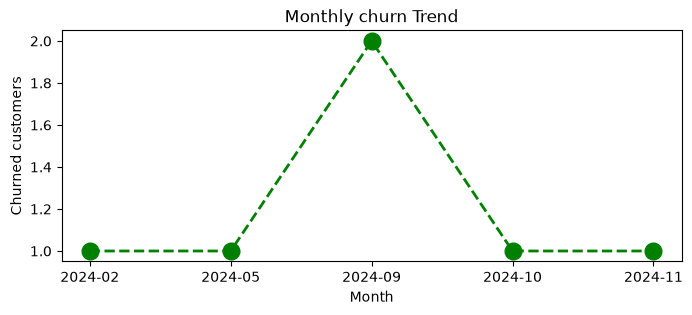

In [73]:
# 4.1 Monthly churn Trend (tie series KPI)

df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend =  df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()


plt.figure(figsize=(8,3)) 
plt.plot(churn_trend.index.astype(str),churn_trend.values,  color='green', marker='o', linestyle='dashed',      linewidth=2, markersize=12)

plt.title('Monthly churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned customers')
plt.show()

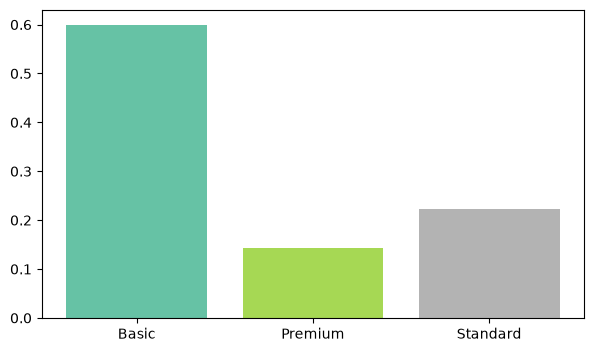

In [80]:
# 4.2 Churn by plan_type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

# colors =['yellow','purple','blue'] # direct color add
colors = plt.cm.Set2(np.linspace(0,1,len(churn_plan))) # rendom color add

plt.figure(figsize=(7,4))

plt.bar(churn_plan.index, churn_plan.values, color = colors)
plt.show()

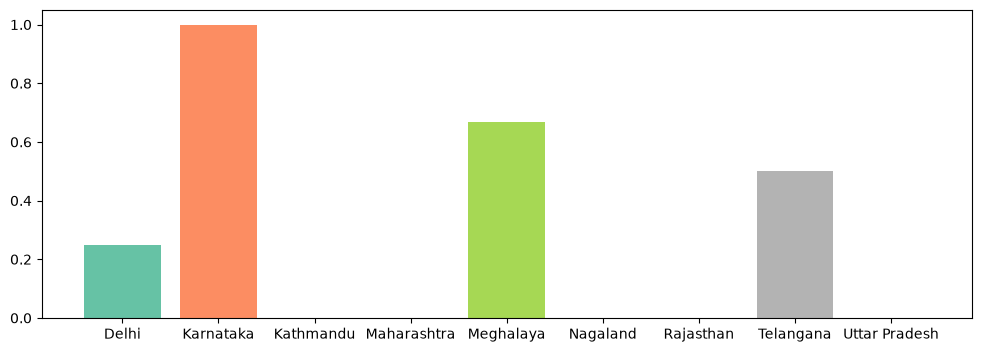

In [82]:
# 4.3 Churn by State 
churn_plan = df_visual.groupby('state')['churn_flag'].mean()

# colors =['yellow','purple','blue'] # direct color add
colors = plt.cm.Set2(np.linspace(0,1,len(churn_plan))) # rendom color add

plt.figure(figsize=(12,4))

plt.bar(churn_plan.index, churn_plan.values, color = colors)
plt.show()

In [83]:
# Visulaization using Seaborn

In [84]:
# encoding - convert str to numeric so that wecan find corr between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

In [89]:
df_visual[['plan_type', 'contract_type','churn_score', 'churn_flag', 'escalations','churn_risk' ]].head()

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,Standard,Annual,12,0,0,low
1,Premium,Annual,91,1,1,high
2,Basic,Monthly,34,0,0,low
3,Premium,Annual,8,0,0,low
4,Standard,Monthly,88,1,1,high


In [86]:
df_encoded = df[['plan_type', 'contract_type','churn_score', 'churn_flag', 'escalations','churn_risk' ]]

categorial_cols = ['plan_type','contract_type','churn_risk']

 for col in categorial_cols:
     df_encoded[col] = df_encoded[col].astype('category').cat.codes

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,Standard,Annual,12,0,0,low
1,Premium,Annual,91,1,1,high
2,Basic,Monthly,34,0,0,low
3,Premium,Annual,8,0,0,low
4,Standard,Monthly,88,1,1,high


In [93]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,2,0,12,0,0,1
1,1,0,91,1,1,0
2,0,1,34,0,0,1
3,1,0,8,0,0,1
4,2,1,88,1,1,0


In [95]:
import warnings
warnings.filterwarnings("ignore")

In [98]:
# incorrect method of encoding - as numbers are not assigned based on prority
df_encoded = df[['plan_type', 'contract_type','churn_score', 'churn_flag', 'escalations','churn_risk' ]]

categorial_cols = ['plan_type','contract_type','churn_risk']

for col in categorial_cols:
     df_encoded[col] = df_encoded[col].astype('category').cat.codes

In [92]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,2,0,12,0,0,1
1,1,0,91,1,1,0
2,0,1,34,0,0,1
3,1,0,8,0,0,1
4,2,1,88,1,1,0


<Axes: >

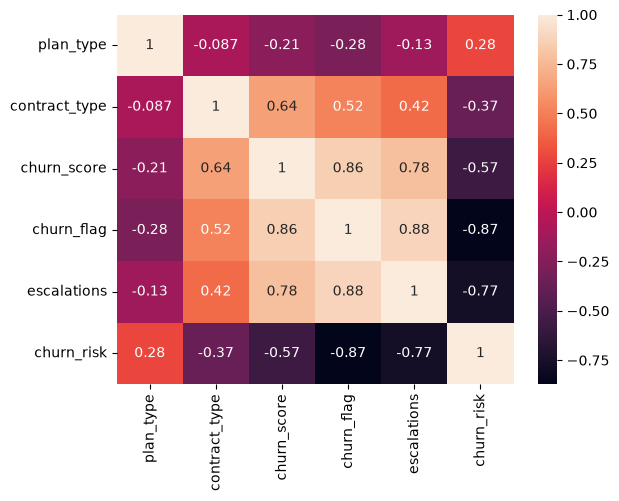

In [97]:
# Heatmap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot = True)

In [102]:
df_visual['churn_risk'].unique()

array(['low', 'high', 'med'], dtype=object)

In [105]:
# Correct method of encoding - based on prority
df_encoded = df_visual[['plan_type', 'contract_type','churn_score', 'churn_flag', 'escalations','churn_risk' ]]

order_mappings = {
    'plan_type' : ['Basic','Standard', 'Premium'], 
    'contract_type' :['Monthly','Annual'],
    'churn_risk':['low', 'high', 'med']
}

for col,order in order_mappings.items():
     df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'),categories=order, ordered=True).codes

In [108]:
 df_visual[['plan_type', 'contract_type','churn_score', 'churn_flag', 'escalations','churn_risk' ]].head()

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,Standard,Annual,12,0,0,low
1,Premium,Annual,91,1,1,high
2,Basic,Monthly,34,0,0,low
3,Premium,Annual,8,0,0,low
4,Standard,Monthly,88,1,1,high


In [107]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,1,1,12,0,0,0
1,2,1,91,1,1,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,1,1


<Axes: >

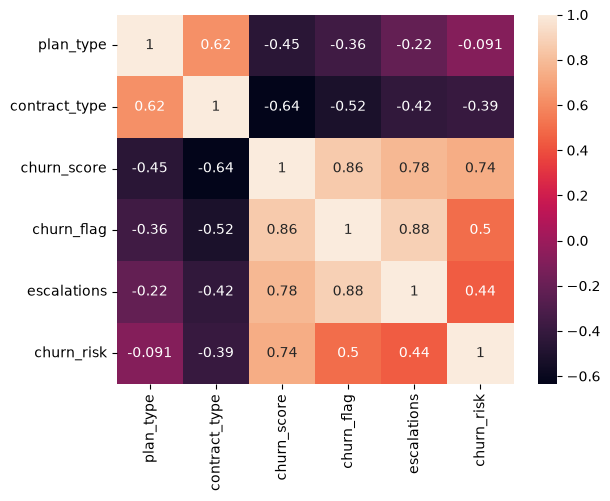

In [109]:
# Heatmap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot = True)

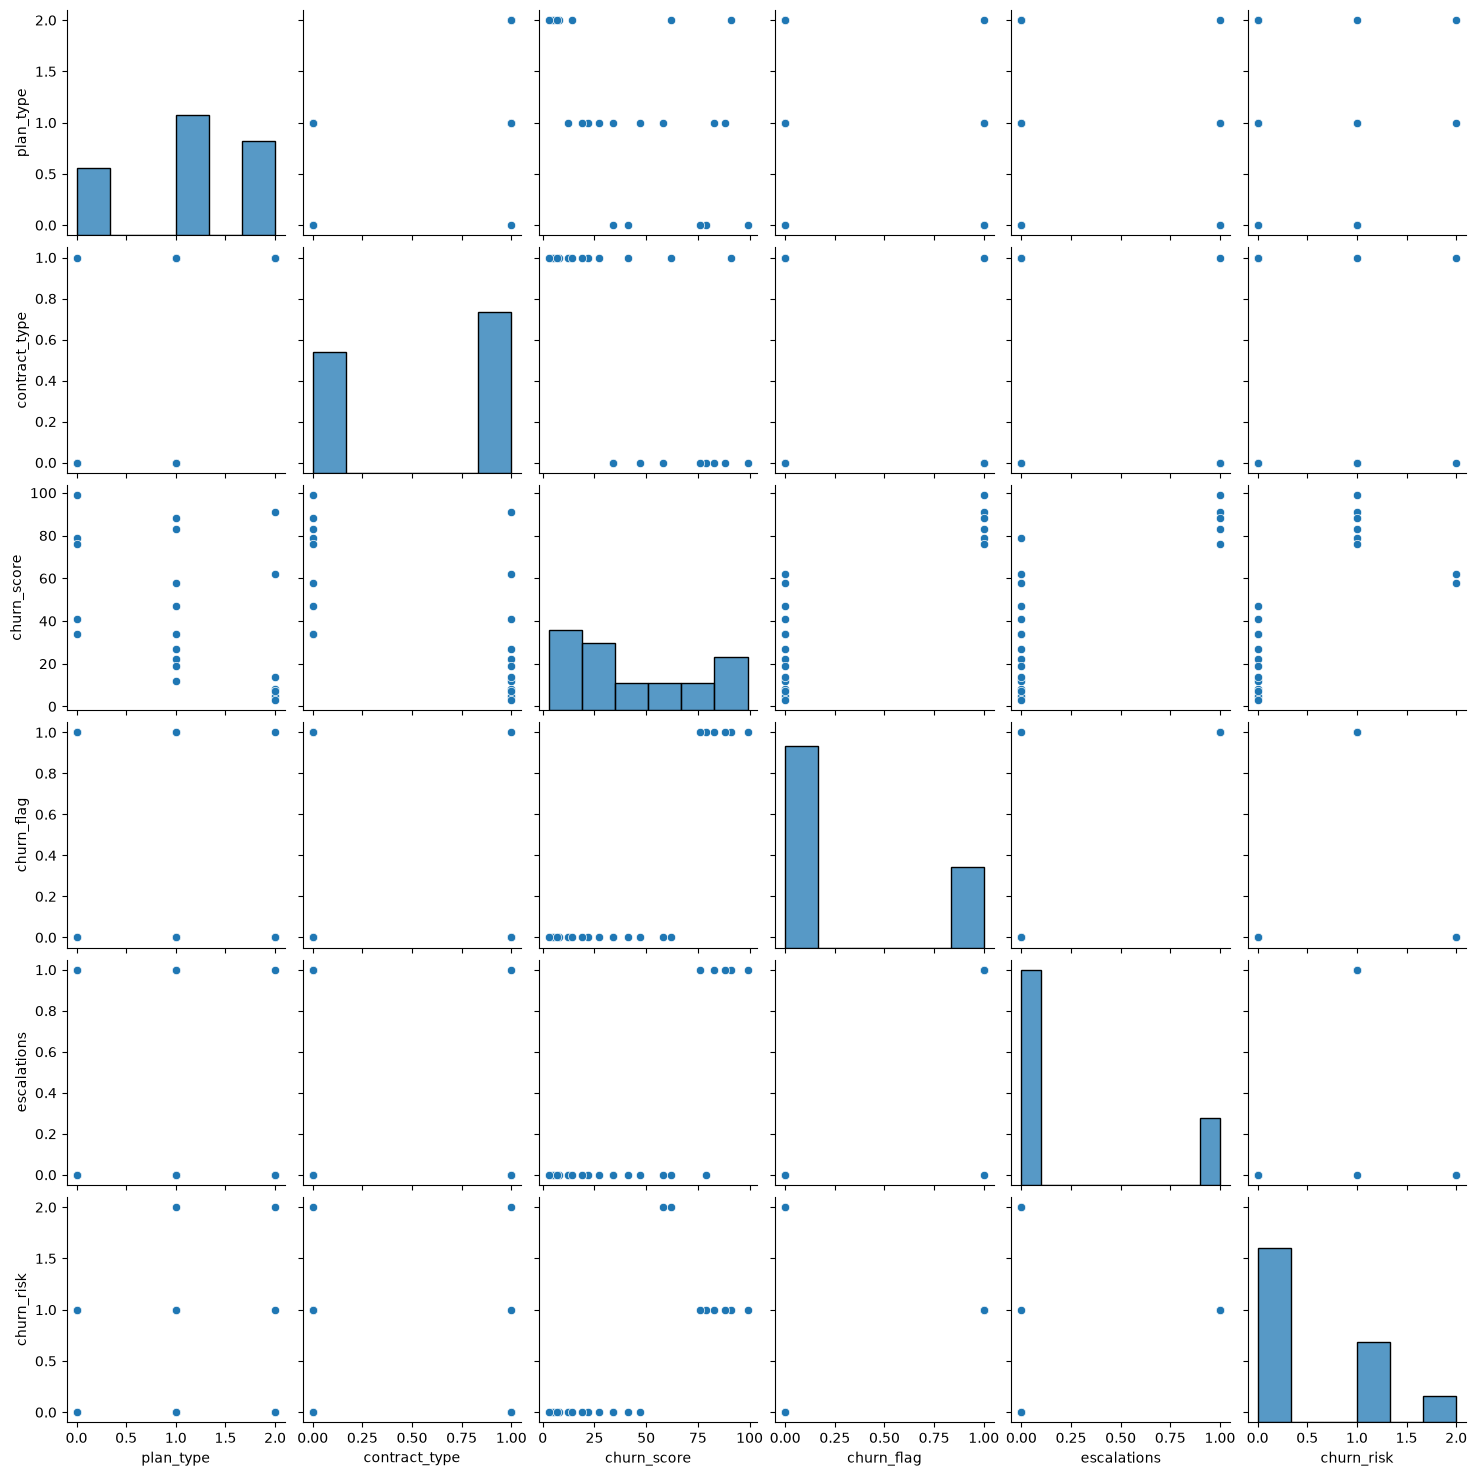

In [110]:
# pairplot - relationship in  a dataset
sns.pairplot(df_encoded)

In [111]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

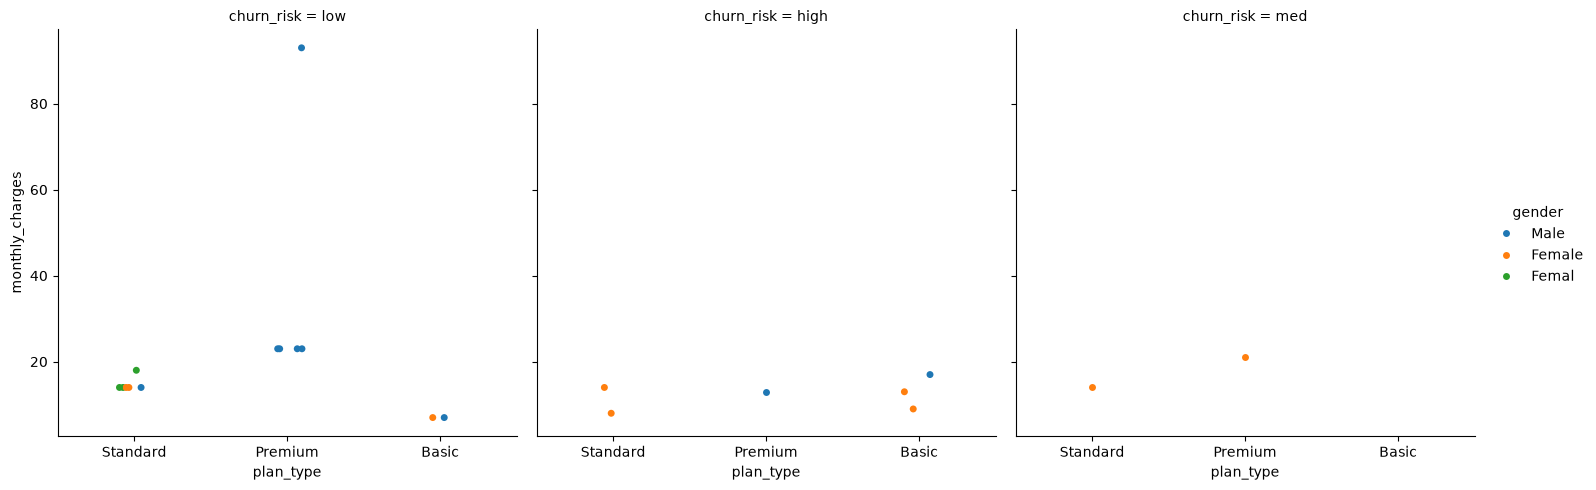

In [114]:
# catplt/Facefrid plot - multi-dim comparison

sns.catplot(data =df_visual,
            x='plan_type',
            y='monthly_charges',
            hue='gender',
            col='churn_risk',)

In [115]:
# Pivot Table

In [118]:
pd.pivot_table(
    df_visual,
    values='churn_flag',
    index='plan_type',
    aggfunc ='mean'
)

,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [119]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

In [120]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges','customerid','churn_flag'],  
    aggfunc ={
        'monthly_charges':'sum',
        'customerid' : 'nunique',
        'churn_flag' :'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


In [121]:
# Working wirh SQL in Python (pandas)

In [8]:
# Create database in sql
conn = sqlite3.connect('test_database.sqlite')

#table details
conn.execute("CREATE TABLE users(first_name TEXT,country TEXT, budget INTEGER)")

#commit and save
conn.commit()

In [7]:
#insert data
#conn = sqlite3.connect('test_database.sqlite')
cursor = conn.cursor()

#Write sql query to insert records in sql tables
cursor.execute(
  """
     INSERT INTO users VALUES 
       ('Madhav','india',5000),
       ('Rishabh', 'Germany',2500),
       ('Vishakha','India',3500)
     
    """
)
#commit and save
conn.commit()
print("Data Inserted successfully!")

Data Inserted successfully!


In [9]:
# check inserted data in table
conn = sqlite3.connect('test_database.sqlite')
query = """ SELECT * FROM users"""

df_results = pd.read_sql(query,conn)

df_results .head()

,first_name,country,budget
0,Madhav,india,5000
1,Rishabh,Germany,2500
2,Vishakha,India,3500


In [13]:
#addregation 
query = """
       SELECT country, sum(budget) as total_budget
       from users 
       GROUP BY country
"""
df_agg = pd.read_sql(query,conn)

df_agg.head()

,country,total_budget
0,Germany,2500
1,India,8500


In [12]:
query = """
    UPDATE users
    SET country = 'India'
    WHERE country = 'india'
"""

cursor = conn.cursor()
cursor.execute(query)
conn.commit()

In [14]:
# always closethe conn with db once the task is over
conn.close()